# DS203 Project: Forecasting U.S. Inflation

In this project, we are using monthly U.S. macroeconomic data from the Federal Reserve Economic Data (FRED) database. We predict year-over-year inflation for 1, 3, 6, and 12 months ahead. We are comparing three regression models (Ordinary Least Squares Linear Regression, Ridge Regression, and Lasso Regression). THus, examine how predictive accuracy changes as we look further into the future, identifying which macroeconomic indicators are most useful for forecasting inflation.

**Inflation definition:**(formula)
$$\text{Inflation}_t = 100 \times \left( \frac{\text{CPI}_t}{\text{CPI}_{t-12}} - 1 \right)$$

**What we are doing:**
1. Load the 11 FRED series and align them to a common monthly frequency
2. Restrict to the common period, engineer growth and lag features, and build target columns
3. Explore the data (EDA): summary statistics, outlier detection, correlations, and lead-lag analysis
4. Split the data chronologically into training, validation, and test sets without data leakage
5. Build Scikit-Learn pipelines, train models, and tune hyperparameters on the validation set
6. Evaluate the final models on the unseen test set using MAE, RMSE, and $R^2$
7. Examine feature importance using standardized model coefficients and macro-only models
8. Discuss the results, economic insights, and limitations

**Group members:**
1. Raunak Roy, 25B2254
2. Fulsundar Yash Shrikant, 25B2165
3. Dhruv Deorah, 25B2275

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

random_state = 42
horizons = [1, 3, 6, 12]

# Draw a colour-coded heatmap from a table of numbers
def plot_heatmap(data, title, figsize=(10, 7), vmin=-1, vmax=1, fmt=".2f"):
    plt.figure(figsize=figsize)
    sns.heatmap(data, annot=True, cmap="coolwarm", vmin=vmin, vmax=vmax, fmt=fmt, linewidths=0.5)
    plt.title(title)
    plt.tight_layout()
    plt.show()

## 1. Data Loading

We downloaded the full history of the 11 series from FRED as CSV files:
* Price indices: `CPIAUCSL` (Consumer Price Index), `PPIACO` (Producer Price Index)
* Labor market: `UNRATE` (Unemployment Rate), `PAYEMS` (Nonfarm Payrolls)
* Production and activity: `INDPRO` (Industrial Production), `HOUST` (Housing Starts)
* Interest rates & financial: `FEDFUNDS` (Federal Funds Rate), `T10Y2Y` (10-Year minus 2-Year Treasury Spread), `M2SL` (M2 Money Supply)
* Commodity & sentiment: `DCOILWTICO` (WTI Crude Oil Price), `UMCSENT` (Consumer Sentiment)

`T10Y2Y` and `DCOILWTICO` are daily, so we aggregate them to monthly averages using `groupby()`. The other nine series are already monthly. All dates are aligned to month-start that is year-month-01 format so the series line up.

In [ ]:
all_series = ["T10Y2Y", "UNRATE", "INDPRO", "FEDFUNDS", "PAYEMS", "PPIACO",
              "HOUST", "DCOILWTICO", "M2SL", "UMCSENT", "CPIAUCSL"]

data_dict = {}
raw_log = []

# Loads and reads each file and converts it into a monthly series
for sid in all_series:
    file_path = sid + ".csv"
    if not os.path.exists(file_path):
        file_path = os.path.join("data", sid + ".csv")

    t = pd.read_csv(file_path)
    t["observation_date"] = pd.to_datetime(t["observation_date"])
    t[sid] = pd.to_numeric(t[sid], errors="coerce")
    t = t.dropna(subset=["observation_date"])
    t = t.sort_values(by="observation_date")

    # Make date month-start so all series line up
    year_str = t["observation_date"].dt.year.astype(str)
    month_str = t["observation_date"].dt.month.astype(str).str.zfill(2)
    t["month"] = pd.to_datetime(year_str + "-" + month_str + "-01")

    # Spacing in days between observations
    spacing_days = (t["observation_date"] - t["observation_date"].shift(1)).dt.days
    median_spacing = spacing_days.median()

    raw_log.append({
        "series": sid.lower(),
        "start": str(t["observation_date"].min().date()),
        "end": str(t["observation_date"].max().date()),
        "rows": len(t),
        "missing": int(t[sid].isnull().sum()),
        "median_spacing_days": median_spacing,
        "frequency": "daily" if median_spacing <= 7 else "monthly"
    })

    # Monthly average for daily series, this becomes the exact value for monthly series
    m = t.groupby("month")[sid].mean()
    m.name = sid.lower()
    data_dict[sid.lower()] = m

# Merge all series into a single monthly table
monthly = pd.DataFrame(data_dict)
monthly = monthly.sort_index()

raw_summary = pd.DataFrame(raw_log)
print("Raw FRED Series Summary")
print(raw_summary)
print("Shape of merged monthly table:", monthly.shape)
monthly.tail()

Raw FRED Series Summary
        series       start         end   rows  missing  median_spacing_days  \
0       t10y2y  1976-06-01  2026-11-20  13169      554                  1.0   
1       unrate  1948-01-01  2026-10-01    946        1                 31.0   
2       indpro  1919-01-01  2026-10-01   1294        0                 31.0   
3     fedfunds  1954-07-01  2026-10-01    868        0                 31.0   
4       payems  1939-01-01  2026-10-01   1054        0                 31.0   
5       ppiaco  1913-01-01  2026-10-01   1366        0                 31.0   
6        houst  1959-01-01  2026-10-01    814        0                 31.0   
7   dcoilwtico  1986-01-02  2026-11-17  10664     1117                  1.0   
8         m2sl  1959-01-01  2026-09-01    813        0                 31.0   
9      umcsent  1952-11-01  2026-09-01    887      210                 31.0   
10    cpiaucsl  1947-01-01  2026-10-01    958        1                 31.0   

   frequency  
0      daily

,t10y2y,unrate,indpro,fedfunds,payems,ppiaco,houst,dcoilwtico,m2sl,umcsent,cpiaucsl
month,,,,,,,,,,,
2026-07-01,0.376818,4.1,103.1675,3.63,158882.0,284.837,1369.0,80.456364,23177.4,55.2,332.813
2026-08-01,0.468095,4.1,103.0954,3.63,159068.0,287.522,1280.0,83.897619,23300.9,51.7,334.131
2026-09-01,0.337619,4.2,103.8458,3.75,159128.0,294.473,1191.0,97.308095,23413.9,48.1,336.298
2026-10-01,0.387619,4.1,103.3954,3.88,159293.0,293.921,1309.0,102.066364,NaN,NaN,337.476
2026-11-01,0.301429,NaN,NaN,NaN,NaN,NaN,NaN,92.710000,NaN,NaN,NaN


## 2. Common Period, Feature Engineering, and Targets

**Common period:** We have to start from the latest first date among all series (`dcoilwtico`, which begins in January 1986) and tehn end where all series will have data at same time. So in this way every variable has complete data for every month in this range.

**Target:** For each of horizon *n*, the target is the inflation *n* months later.
that is created in Pandas using df['inflation'].shift(-n).

**Features:** All of them use only data available up to month *t*:
* `inflation`: its the current month's YoY inflation rate
* `unrate`: current unemployment rate, and `d_unrate`: it is calculated as the monthly change in unemployment.
* `y_indpro`, `y_payems`, `y_ppiaco`, `y_dcoilwtico`, `y_m2sl`: 12-month percentage growth of these series, this is so because the raw levels keep rising over time.
* `t10y2y`, `fedfunds`, `houst`, `umcsent`: are used directly in levels

Rows at the start (12-month a warm-up for growth) and at the end (missing future targets) are removed with `dropna()`.

In [ ]:
# Find the common time period where all series have data
starts = []
ends = []
for col in monthly.columns:
    valid_dates = monthly[col].dropna().index
    starts.append(valid_dates[0])
    ends.append(valid_dates[-1])

start = max(starts)
end = min(ends)
common = monthly.loc[start:end].copy()

# Make inflation and unemployment features
df = pd.DataFrame(index=common.index)
df["inflation"] = (common["cpiaucsl"] / common["cpiaucsl"].shift(12) - 1.0) * 100.0
df["unrate"] = common["unrate"]
df["d_unrate"] = common["unrate"] - common["unrate"].shift(1)

# Year-over-year growth for these series
for c in ["indpro", "payems", "ppiaco", "dcoilwtico", "m2sl"]:
    df[f"y_{c}"] = (common[c] / common[c].shift(12) - 1.0) * 100.0

# Copy these series as they are
for c in ["t10y2y", "fedfunds", "houst", "umcsent"]:
    df[c] = common[c]

# Targets: inflation n months in the future
for n in horizons:
    df[f"target_{n}m"] = df["inflation"].shift(-n)

features = ["inflation", "unrate", "d_unrate", "y_indpro", "y_payems", "y_ppiaco",
            "y_dcoilwtico", "y_m2sl", "t10y2y", "fedfunds", "houst", "umcsent"]

macro_features = [f for f in features if f != "inflation"]
targets = [f"target_{n}m" for n in horizons]

# We keep only rows where features and targets all exist
model_data = df[features + targets].dropna()

print(f"Common available period: {start.date()} to {end.date()} ({len(common)} months)")
print(f"Modeling sample size: {model_data.index.min().date()} to {model_data.index.max().date()} ({len(model_data)} months)")

# Checking for unexpected missing values inside the sample
last_date = df["inflation"].dropna().index[-1]
missing_inside = []
for d in df.index[12:]:
    if d <= last_date:
        if df.loc[d, features].isnull().any():
            missing_inside.append(str(d.date()))
print("Unexpected missing months inside sample:", missing_inside if len(missing_inside) > 0 else "None")

Common available period: 1986-01-01 to 2026-09-01 (489 months)
Modeling sample size: 1987-01-01 to 2025-08-01 (461 months)
Unexpected missing months inside sample: ['2025-10-01', '2025-11-01']


## 3. Exploratory Data Analysis (EDA)

### 3.1 Inspect the dataset (dates, size, data types, missing values, summary statistics)
We report the dataset shape, data types, missing values, and summary statistics across all modeling variables.

In [ ]:
print("Common Period Missing Values")
print(common.isnull().sum())

print("Engineered Table Info")
print("Shape:", df.shape)
print("Data Types:", df.dtypes)

print("Summary Statistics of Modeling Sample")
# Summary of statistics for each feature
summary_stats = model_data[features].describe().T
print(summary_stats)

Common Period Missing Values
t10y2y        0
unrate        1
indpro        0
fedfunds      0
payems        0
ppiaco        0
houst         0
dcoilwtico    0
m2sl          0
umcsent       0
cpiaucsl      1
dtype: int64
Engineered Table Info
Shape: (489, 16)
Data Types: inflation       float64
unrate          float64
d_unrate        float64
y_indpro        float64
y_payems        float64
y_ppiaco        float64
y_dcoilwtico    float64
y_m2sl          float64
t10y2y          float64
fedfunds        float64
houst           float64
umcsent         float64
target_1m       float64
target_3m       float64
target_6m       float64
target_12m      float64
dtype: object
Summary Statistics of Modeling Sample
              count         mean         std         min          25%  \
inflation     461.0     2.815220    1.607302   -1.958761     1.759505   
unrate        461.0     5.692191    1.681169    3.400000     4.400000   
d_unrate      461.0    -0.005423    0.535838   -2.200000    -0.100000   
y_i

### 3.2 Inflation over time: regime identification

We plot inflation over time and mark key macroeconomic regimes:
* **Low inflation:** Periods below 2%
* **High inflation:** Periods at or above 5%
* **Deflation:** Periods below 0%
* **Rapid changes:** Months with the largest monthly changes ($|\Delta \text{Inflation}|$ in top 10%)

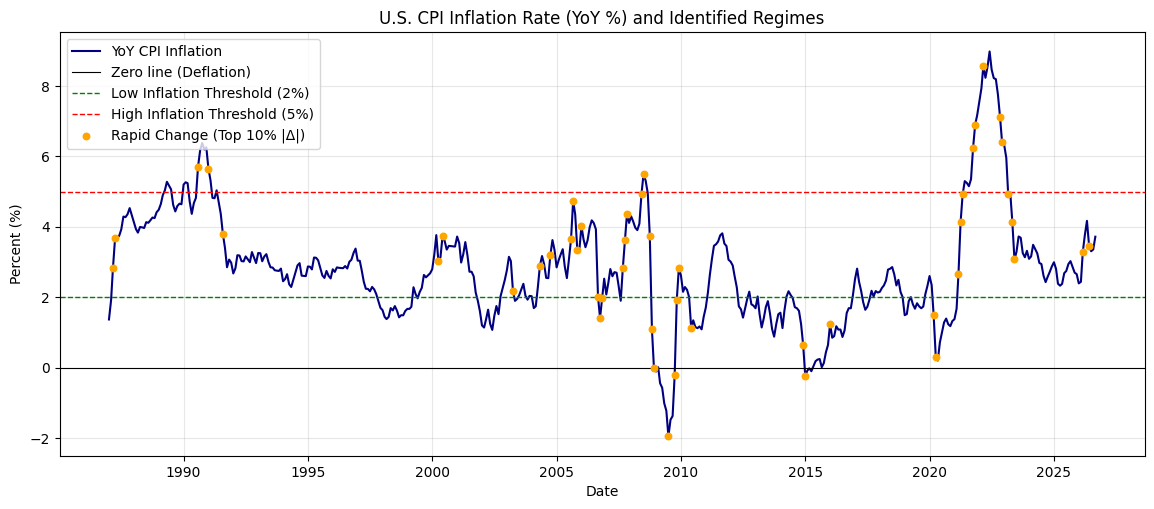

Peak Inflation   : 8.98% on 2022-06-01 (Post-COVID shock)
Trough Inflation : -1.96% on 2009-07-01 (2008 Financial Crisis deflation)
Top 5 Largest Month-to-Month Inflation Moves:
  2008-11-01: -2.63 percentage points
  2009-11-01: +2.14 percentage points
  2006-09-01: -1.91 percentage points
  2021-04-01: +1.47 percentage points
  2008-10-01: -1.22 percentage points


In [ ]:
infl = df["inflation"].dropna()
changes = (infl - infl.shift(1)).abs()
rapid_threshold = changes.quantile(0.90)
rapid_points = changes >= rapid_threshold

# Ploting inflation over time and mark regimes
plt.figure(figsize=(14, 5.5))
plt.plot(infl.index, infl, color="navy", lw=1.5, label="YoY CPI Inflation")

# Defiining reference threshold lines
plt.axhline(0, color="black", lw=0.8, ls="-", label="Zero line (Deflation)")
plt.axhline(2.0, color="green", lw=1.0, ls="--", label="Low Inflation Threshold (2%)")
plt.axhline(5.0, color="red", lw=1.0, ls="--", label="High Inflation Threshold (5%)")

# Mark teh months with rapid change as orange dots
plt.scatter(infl.index[rapid_points], infl[rapid_points], color="orange", s=22, zorder=4, label="Rapid Change (Top 10% |Δ|)")

plt.title("U.S. CPI Inflation Rate (YoY %) and Identified Regimes")
plt.xlabel("Date")
plt.ylabel("Percent (%)")
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.show()

# Find the highest and lowest inflation rates and when they happened
peak_val = infl.max()
peak_date = infl[infl == peak_val].index[0]
trough_val = infl.min()
trough_date = infl[infl == trough_val].index[0]

print(f"Peak Inflation   : {peak_val:.2f}% on {peak_date.date()} (Post-COVID shock)")
print(f"Trough Inflation : {trough_val:.2f}% on {trough_date.date()} (2008 Financial Crisis deflation)")

# Finding the five largest month-to-month changes
print("Top 5 Largest Month-to-Month Inflation Moves:")
top5_indices = changes.sort_values(ascending=False).head(5).index
for d in top5_indices:
    move = infl.loc[d] - infl.shift(1).loc[d]
    print(f"  {d.date()}: {move:+.2f} percentage points")

### 3.3 Feature distributions, skewness, volatility, and outliers

Here we examine the distribution of each feature:
* **Ranges and dispersion:** Mean, standard deviation, min, max, range, and quartiles ($Q_1, Q_3$).
* **Skewness:** Skewness coefficient computed using `.skew()`.
* **Volatility:** Standard deviation of the monthly change ($\Delta X_t$).
* **Outliers:** Evaluated using two standard rules:
  1. **IQR rule:** Values outside $[Q_1 - 1.5 \times \text{IQR}, Q_3 + 1.5 \times \text{IQR}]$.
  2. **Z-score rule:** Standardized observations with $|Z| > 3$.

Feature Distributions and Outlier Statistics
                 Mean     Std     Min      Max    Range  Skewness  Volatility  \
inflation        2.82    1.61   -1.96     8.98    10.94      0.82        0.40   
unrate           5.69    1.68    3.40    14.80    11.40      1.31        0.52   
d_unrate        -0.01    0.54   -2.20    10.40    12.60     15.69        0.73   
y_indpro         1.65    4.12  -17.32    16.55    33.87     -1.39        1.39   
y_payems         1.24    2.25  -13.39    10.86    24.25     -1.97        0.99   
y_ppiaco         2.64    5.76  -16.06    22.69    38.74      0.66        1.50   
y_dcoilwtico     9.91   36.85  -74.09   272.96   347.05      1.39       17.82   
y_m2sl           5.71    4.12   -4.66    26.78    31.43      1.88        0.75   
t10y2y           0.98    0.90   -0.93     2.83     3.76      0.22        0.14   
fedfunds         3.24    2.65    0.05     9.85     9.80      0.34        0.20   
houst         1338.82  370.28  478.00  2273.00  1795.00     -0.3

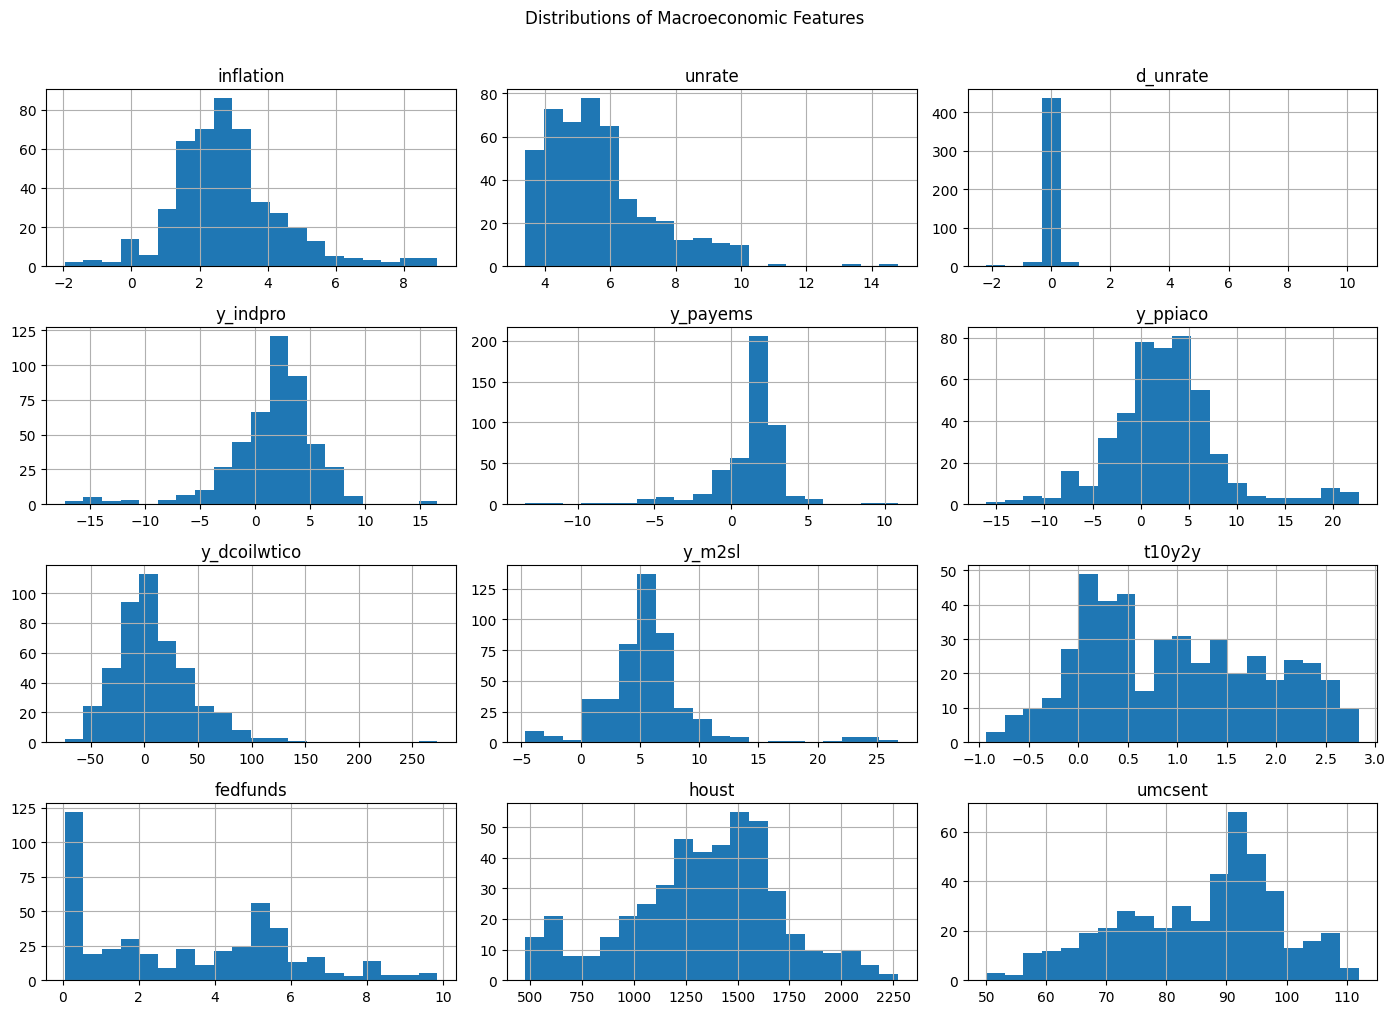

/tmp/ipykernel_387/1444487700.py:41: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([z[col].values for col in features], labels=features, vert=False)


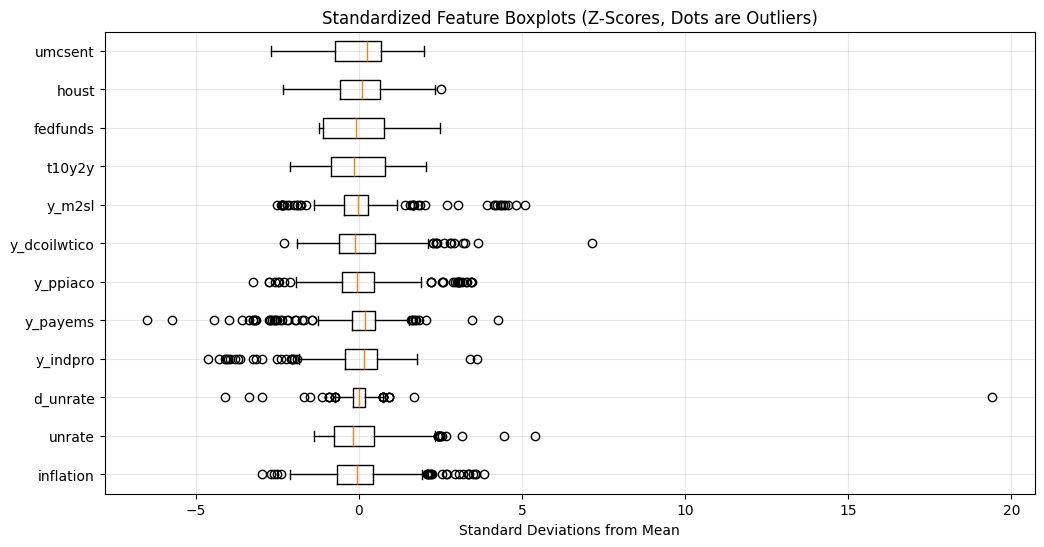

Most Skewed Features:
d_unrate    15.69
y_payems     1.97
y_m2sl       1.88
dtype: float64


In [ ]:
# Take feature columns and standardise them (z-score)
x = model_data[features]
z = (x - x.mean()) / x.std()

# Quartiles and Iqr for outlier detection
q1 = x.quantile(0.25)
q3 = x.quantile(0.75)
iqr = q3 - q1

# Counting outliers using IQR rule and z-score rule
iqr_outliers = ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()
z_outliers = (z.abs() > 3).sum()

# Volatility: basically the standard deviation of month-to-month change
volatility = (df[features] - df[features].shift(1)).std()

# Summary table of distrubutions and outliers
dist_table = pd.DataFrame({
    "Mean": x.mean().round(2),
    "Std": x.std().round(2),
    "Min": x.min().round(2),
    "Max": x.max().round(2),
    "Range": (x.max() - x.min()).round(2),
    "Skewness": x.skew().round(2),
    "Volatility": volatility.round(2),
    "IQR Outliers": iqr_outliers,
    "|Z|>3 Outliers": z_outliers
})

print("Feature Distributions and Outlier Statistics")
print(dist_table)

# Histograms showing the distribution of each feature
x.hist(bins=20, figsize=(14, 10))
plt.suptitle("Distributions of Macroeconomic Features", y=1.01)
plt.tight_layout()
plt.show()

# Boxplot of all standardized features to inspect outliers
plt.figure(figsize=(12, 6))
plt.boxplot([z[col].values for col in features], labels=features, vert=False)
plt.title("Standardized Feature Boxplots (Z-Scores, Dots are Outliers)")
plt.xlabel("Standard Deviations from Mean")
plt.grid(True, alpha=0.3)
plt.show()

# Print the 3 most skewed features
print("Most Skewed Features:")
print(x.skew().abs().sort_values(ascending=False).head(3).round(2))

### 3.4 Contemporaneous relationships with current inflation

Here we check how each feature is correlated with current inflation in the same month ($t$ vs $t$). We draw a heatmap of the correlation matrix, a bar chart of correlations with inflation, and scatter plots for each predictor.

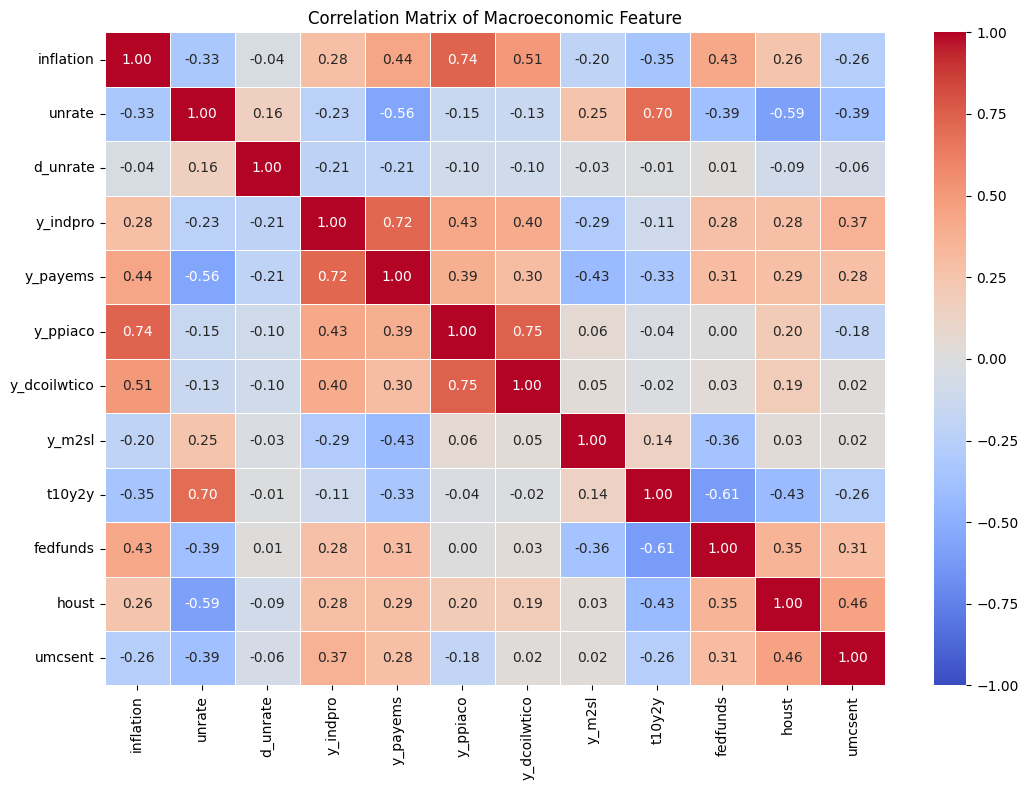

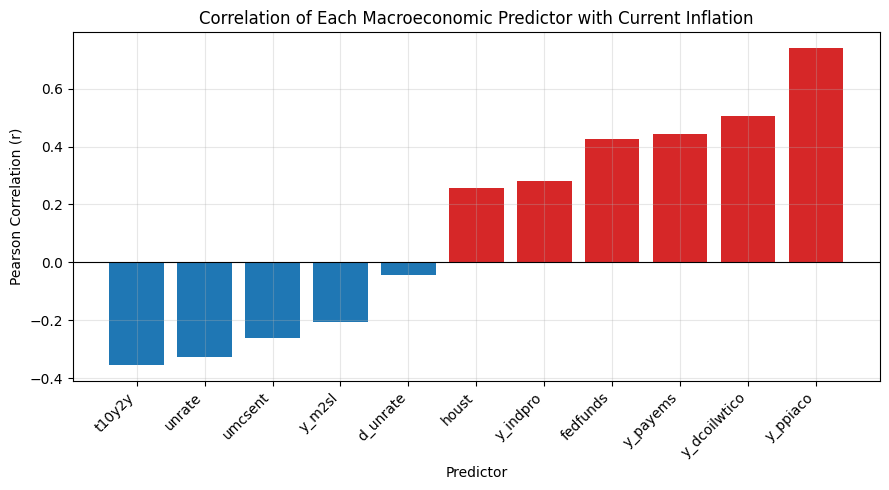

Contemporaneous Correlations with Inflation (Highest to Lowest):
y_ppiaco        0.740
y_dcoilwtico    0.506
y_payems        0.443
fedfunds        0.425
y_indpro        0.283
houst           0.257
d_unrate       -0.045
y_m2sl         -0.205
umcsent        -0.261
unrate         -0.326
t10y2y         -0.354
Name: inflation, dtype: float64


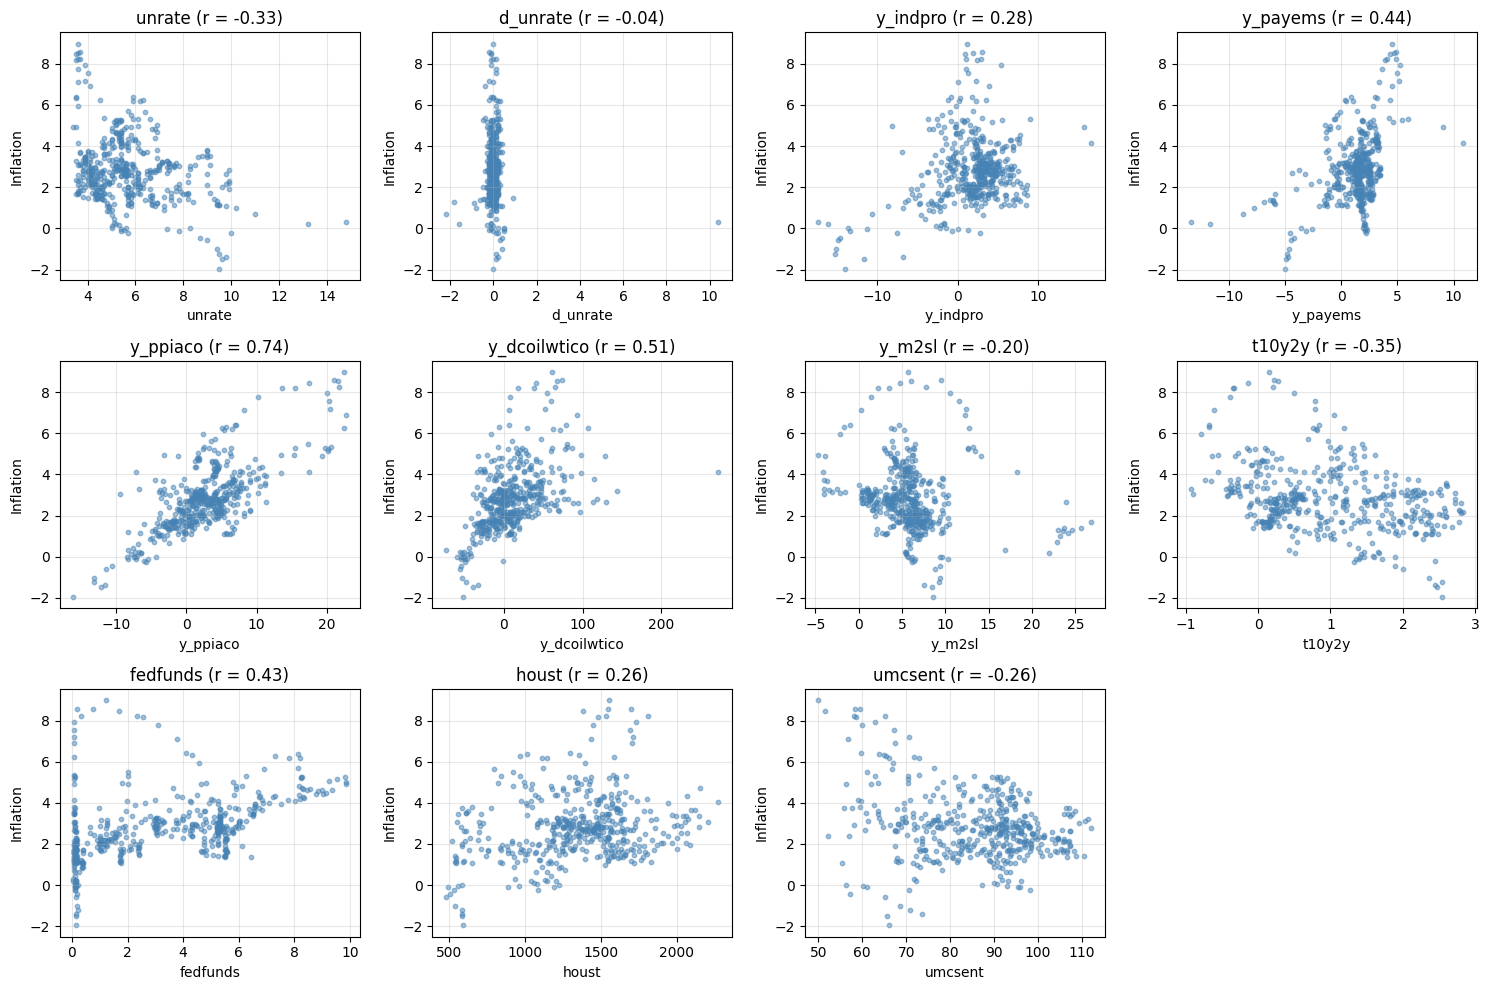

In [ ]:
# Correlation between every pair of features, shown as a heatmap
corr = model_data[features].corr(method="pearson")
plot_heatmap(corr, "Correlation Matrix of Macroeconomic Feature", figsize=(11, 8))

# Correlation of each feature with inflation sorted from low to high
contemp_corr = corr["inflation"].drop("inflation").sort_values()

# Red bars for positive correlation, blue bars for negative
colors = ["tab:red" if val >= 0 else "tab:blue" for val in contemp_corr.values]

# Bar chart of these correlations
plt.figure(figsize=(9, 5))
plt.bar(contemp_corr.index, contemp_corr.values, color=colors)
plt.axhline(0, color="black", lw=0.8)
plt.title("Correlation of Each Macroeconomic Predictor with Current Inflation")
plt.xlabel("Predictor")
plt.ylabel("Pearson Correlation (r)")
plt.xticks(rotation=45, ha="right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Contemporaneous Correlations with Inflation (Highest to Lowest):")
print(contemp_corr.sort_values(ascending=False).round(3))

# Scatter plots of each feataure against current inflation
pred_cols = [c for c in features if c != "inflation"]
plt.figure(figsize=(15, 10))
for i, c in enumerate(pred_cols):
    plt.subplot(3, 4, i + 1)
    plt.scatter(model_data[c], model_data["inflation"], s=10, alpha=0.5, color="steelblue")
    plt.title(f"{c} (r = {contemp_corr[c]:.2f})")
    plt.xlabel(c)
    plt.ylabel("Inflation")
    plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 3.5 Lead–lag analysis across forecasting horizons

We examine how each predictor at month $t$ relates to inflation at $t+n$ ($n \in \{1, 3, 6, 12\}$):
1. **Level correlation:** $\text{corr}(X_t, \text{Inflation}_{t+n})$
2. **Change correlation:** $\text{corr}(X_t, \text{Inflation}_{t+n} - \text{Inflation}_t)$ to see what information predicts future changes beyond simple persistence.

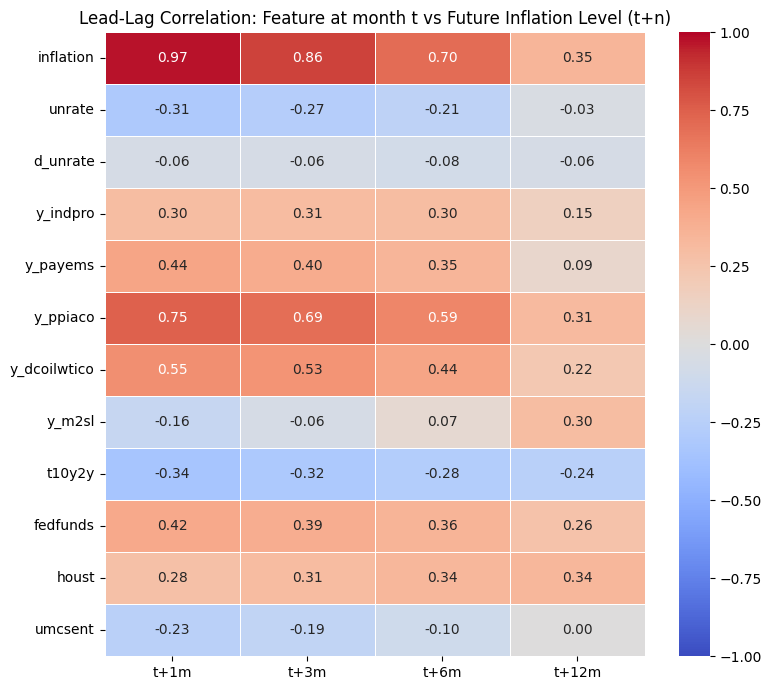

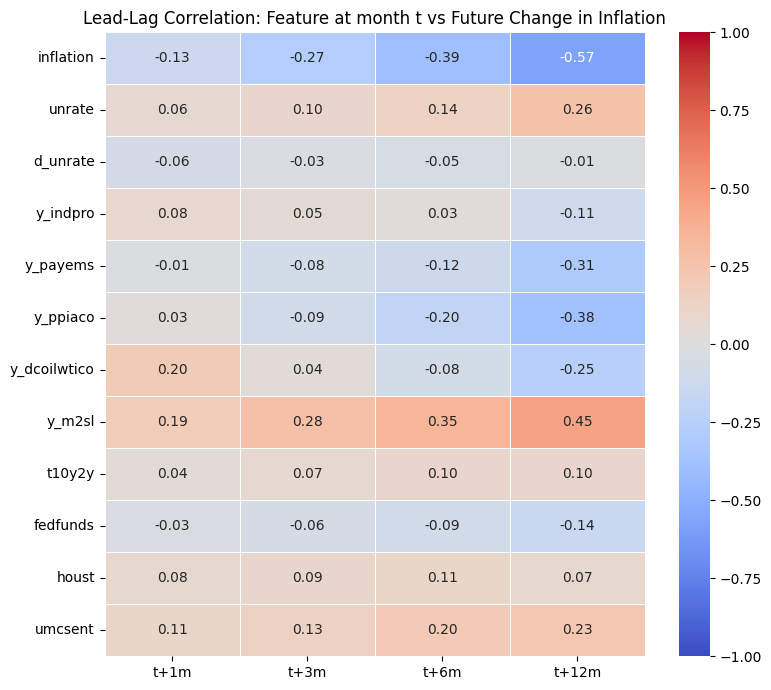

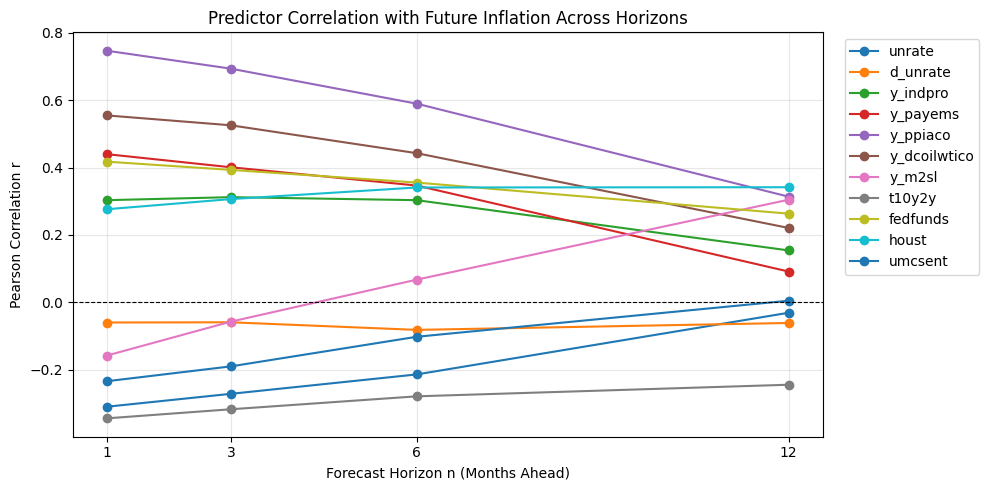

Strongest Macro Predictor (Excluding Inflation) by Absolute Correlation with Future Level:
  t+1m: y_ppiaco (r = 0.747)
  t+3m: y_ppiaco (r = 0.694)
  t+6m: y_ppiaco (r = 0.590)
  t+12m: houst (r = 0.341)


In [ ]:
# Dictionaries to store lead-lag correlations
lead_lag_level = {}
lead_lag_change = {}

for n in horizons:
    target_col = f"target_{n}m"
    col_name = f"t+{n}m"
    level_dict = {}
    change_dict = {}
    for f in features:
        # Correlation of feature today with future inflation level
        level_dict[f] = model_data[f].corr(model_data[target_col])
        # Correlation of feature today with future change in inflation
        change_dict[f] = model_data[f].corr(model_data[target_col] - model_data["inflation"])
    lead_lag_level[col_name] = level_dict
    lead_lag_change[col_name] = change_dict

# Turn dictionaries into tables
lead_lag_df = pd.DataFrame(lead_lag_level)
lead_lag_chg_df = pd.DataFrame(lead_lag_change)

# Heatmaps of both tables
plot_heatmap(lead_lag_df, "Lead-Lag Correlation: Feature at month t vs Future Inflation Level (t+n)", figsize=(8, 7))
plot_heatmap(lead_lag_chg_df, "Lead-Lag Correlation: Feature at month t vs Future Change in Inflation", figsize=(8, 7))

# Line plot of how correlation with future inflation decays with horizon
plt.figure(figsize=(10, 5))
for f in macro_features:
    plt.plot(horizons, lead_lag_df.loc[f].values, marker="o", label=f)
plt.title("Predictor Correlation with Future Inflation Across Horizons")
plt.xlabel("Forecast Horizon n (Months Ahead)")
plt.ylabel("Pearson Correlation r")
plt.xticks(horizons)
plt.axhline(0, color="black", lw=0.8, ls="--")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Strongest predictor for each horizon
print("Strongest Macro Predictor (Excluding Inflation) by Absolute Correlation with Future Level:")
for col in lead_lag_df.columns:
    macro_sub = lead_lag_df[col].drop("inflation").abs()
    top_var = macro_sub[macro_sub == macro_sub.max()].index[0]
    print(f"  {col}: {top_var} (r = {lead_lag_df.loc[top_var, col]:.3f})")

## 4. Dataset Preprocessing: Chronological Split and Leakage Prevention

**Chronological split:** Because this is time-series data, we split observations in time order without random shuffling. Shuffling would use future information to predict the past, causing data leakage.
* **Training set (60%):** Earliest observations used for model fitting
* **Validation set (20%):** Middle observations used for comparing models and tuning $\alpha$
* **Test set (20%):** Most recent observations, kept completely unseen until the final test evaluation

**Preventing data leakage:**
All preprocessing steps (`SimpleImputer` and `StandardScaler`) are fitted **only on the training set** using a Scikit-Learn `Pipeline`, and then applied to validation and test sets unchanged.

Chronological Data Split Summary
              Set  Start Date    End Date  Count
0  Training (60%)  1987-01-01  2009-12-01    276
1       Val (20%)  2010-01-01  2017-08-01     92
2      Test (20%)  2017-09-01  2025-08-01     93


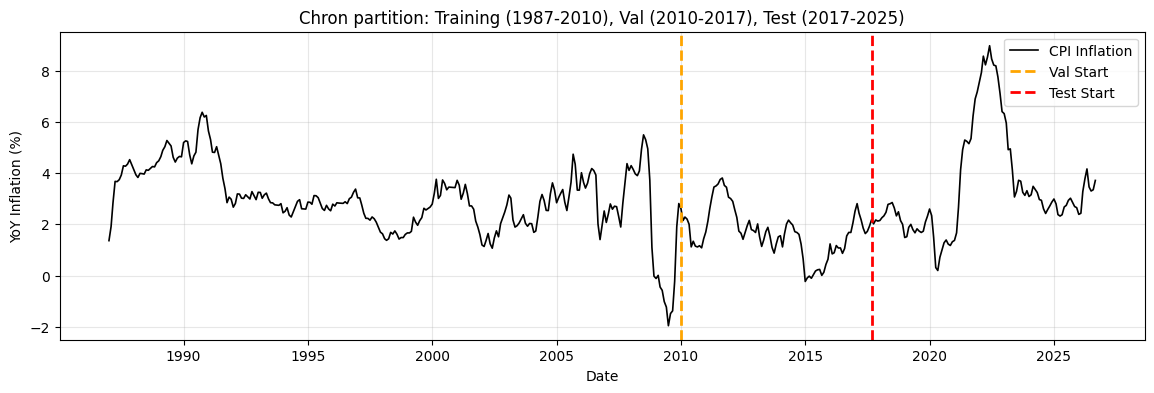

In [ ]:
# Spliting data in chronological/historical order 60% train, 20% validation, 20% test
# The idea is like the model should not use the future data to predict the past or already memorize teh future data
def chrono_split(x, y, train_frac=0.6, val_frac=0.2):
    n = len(x)
    i = int(n * train_frac)
    j = int(n * (train_frac + val_frac))
    return x.iloc[:i], x.iloc[i:j], x.iloc[j:], y.iloc[:i], y.iloc[i:j], y.iloc[j:]

# Summary of chronological splits
X_all = model_data[features]
y_1m = model_data["target_1m"]
xtr, xv, xte, ytr, yv, yte = chrono_split(X_all, y_1m)

split_summary = pd.DataFrame([
    {"Set": "Training (60%)", "Start Date": str(xtr.index.min().date()), "End Date": str(xtr.index.max().date()), "Count": len(xtr)},
    {"Set": "Val (20%)", "Start Date": str(xv.index.min().date()), "End Date": str(xv.index.max().date()), "Count": len(xv)},
    {"Set": "Test (20%)", "Start Date": str(xte.index.min().date()), "End Date": str(xte.index.max().date()), "Count": len(xte)}
])

print("Chronological Data Split Summary")
print(split_summary)

# Plotting time-series split
plt.figure(figsize=(14, 4))
plt.plot(infl.index, infl, color="black", lw=1.2, label="CPI Inflation")
plt.axvline(xv.index[0], color="orange", lw=2, ls="--", label="Val Start")
plt.axvline(xte.index[0], color="red", lw=2, ls="--", label="Test Start")
plt.title("Chron partition: Training (1987-2010), Val (2010-2017), Test (2017-2025)")
plt.xlabel("Date")
plt.ylabel("YoY Inflation (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Interpretation of the split:**
* **Training set (1987–2009, 276 months):** Covers moderate inflation (2%–6%) and the 2008–2009 financial crisis drop below 0%.
* **Validation set (2010–2017, 92 months):** A calm, low-inflation period (mostly 1%–3%).
* **Test set (2017–2025, 93 months):** Contains the 2020 COVID shock and the 2021–2022 inflation spike peaking near 9%, higher than anything in the training period. This makes forecasting on the test set challenging.

## 5. Model Training, Hyperparameter Tuning, and Evaluation

**Models compared:**
1. **LinearRegression:** Standard unregularized Ordinary Least Squares (OLS).
2. **Ridge:** $L_2$-penalized regression that shrinks weights smoothly toward zero, helping with correlated predictors.
3. **Lasso:** $L_1$-penalized regression that sets unhelpful weights strictly to zero, performing feature selection.

**Evaluation metrics:**
Models are evaluated using:
* MAE (Mean Absolute Error)
* RMSE (Root Mean Squared Error)
* $R^2$ (Coefficient of Determination)

**Baseline:**
* **Train Mean Baseline:** It's predicting the average training target $\bar{y}_{\text{train}}$ for every month.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

# Making a single function to calculate MAE, RMSE, and R2
def calc_metrics(y_true, y_pred):
    mae = float(np.mean(np.abs(np.array(y_true) - np.array(y_pred))))
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    r2 = float(r2_score(y_true, y_pred))
    return {"MAE": mae, "RMSE": rmse, "R2": r2}

# We implement pipeline function to use imputer to impute missing values with median
# Then scaling features and fitting the estimator
def make_pipeline(estimator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", estimator)
    ])

# Regularization parameter values used to try for Ridge and Lasso
alphas = np.logspace(-3, 4, 15)
ridge_params = [{"alpha": float(a)} for a in alphas]
lasso_params = [{"alpha": float(a), "max_iter": 10000} for a in alphas]

# Models and parameter grids
model_space = {
    "LinearRegression": (LinearRegression, [{}]),
    "Ridge": (Ridge, ridge_params),
    "Lasso": (Lasso, lasso_params)
}

In [ ]:
# Function to train models, tune alpha on validation set, and evaluate on test set
def run_experiment(feature_cols, experiment_label):
    val_records = []
    test_records = []
    best_models = {}
    fitted_pipelines = {}
    predictions = {}

    for h in horizons:
        target_name = f"target_{h}m"
        X = model_data[feature_cols]
        y = model_data[target_name]

        xtr, xv, xte, ytr, yv, yte = chrono_split(X, y)

        # 1. Hyperparameter tuning on validation set
        best_hp = {}
        for name, (model_cls, param_grid) in model_space.items():
            best_rmse = float("inf")
            best_p = None
            best_pipe = None

            for p in param_grid:
                pipe = make_pipeline(model_cls(**p))
                pipe.fit(xtr, ytr)
                val_pred = pipe.predict(xv)
                val_m = calc_metrics(yv, val_pred)

                val_records.append({
                    "setup": experiment_label,
                    "horizon": h,
                    "model": name,
                    "alpha": p.get("alpha", np.nan),
                    "val_MAE": val_m["MAE"],
                    "val_RMSE": val_m["RMSE"],
                    "val_R2": val_m["R2"]
                })

                # Keep the hyperparameter with lowest validation RMSE
                if val_m["RMSE"] < best_rmse:
                    best_rmse = val_m["RMSE"]
                    best_p = p
                    best_pipe = pipe

            best_hp[name] = (best_rmse, best_p, best_pipe)

        # Select winning model on lowest validation RMSE
        selected_name = min(best_hp.keys(), key=lambda k: best_hp[k][0])
        best_models[h] = {
            "model_name": selected_name,
            "params": best_hp[selected_name][1]
        }

        # 2. Final evaluation on test set (fitted strictly on training data)
        for name in model_space.keys():
            pipe = best_hp[name][2]
            test_pred = pipe.predict(xte)
            test_m = calc_metrics(yte, test_pred)

            test_records.append({
                "setup": experiment_label,
                "horizon": h,
                "model": name,
                "selected": (name == selected_name),
                "test_MAE": test_m["MAE"],
                "test_RMSE": test_m["RMSE"],
                "test_R2": test_m["R2"]
            })

            fitted_pipelines[(h, name)] = pipe
            predictions[(h, name)] = test_pred

        # Baseline: Train Target Mean
        mean_pred = np.full(len(yte), ytr.mean())
        base_m = calc_metrics(yte, mean_pred)
        test_records.append({
            "setup": experiment_label,
            "horizon": h,
            "model": "Baseline: Train Mean",
            "selected": False,
            "test_MAE": base_m["MAE"],
            "test_RMSE": base_m["RMSE"],
            "test_R2": base_m["R2"]
        })
        predictions[(h, "Baseline: Train Mean")] = mean_pred
        predictions[(h, "actual")] = yte.values

    return {
        "val_df": pd.DataFrame(val_records),
        "test_df": pd.DataFrame(test_records),
        "best_models": best_models,
        "fitted": fitted_pipelines,
        "predictions": predictions,
        "test_index": xte.index,
        "features": feature_cols
    }

main_exp = run_experiment(features, "All Features")

### 5.1 Validation set results and model selection

We evaluate each model across values of $\alpha$ on the validation set, and choose the model and $\alpha$ with the lowest validation RMSE.

Validation Set Performance Across Models
     horizon             model    alpha  val_MAE  val_RMSE  val_R2
0          1  LinearRegression      NaN    0.452     0.532   0.669
11         1             Ridge  100.000    0.326     0.452   0.761
19         1             Lasso    0.032    0.244     0.307   0.890
31         3  LinearRegression      NaN    1.206     1.331  -1.084
42         3             Ridge  100.000    0.527     0.667   0.477
51         3             Lasso    0.100    0.491     0.619   0.550
62         6  LinearRegression      NaN    1.606     1.763  -2.650
73         6             Ridge  100.000    0.653     0.829   0.193
82         6             Lasso    0.100    0.646     0.833   0.186
93        12  LinearRegression      NaN    1.783     2.042  -3.667
104       12             Ridge  100.000    0.827     1.044  -0.221
114       12             Lasso    0.316    0.789     1.013  -0.149
Selected Model per Horizon (Lowest Validation RMSE)
Horizon  1m: Lasso              | Be

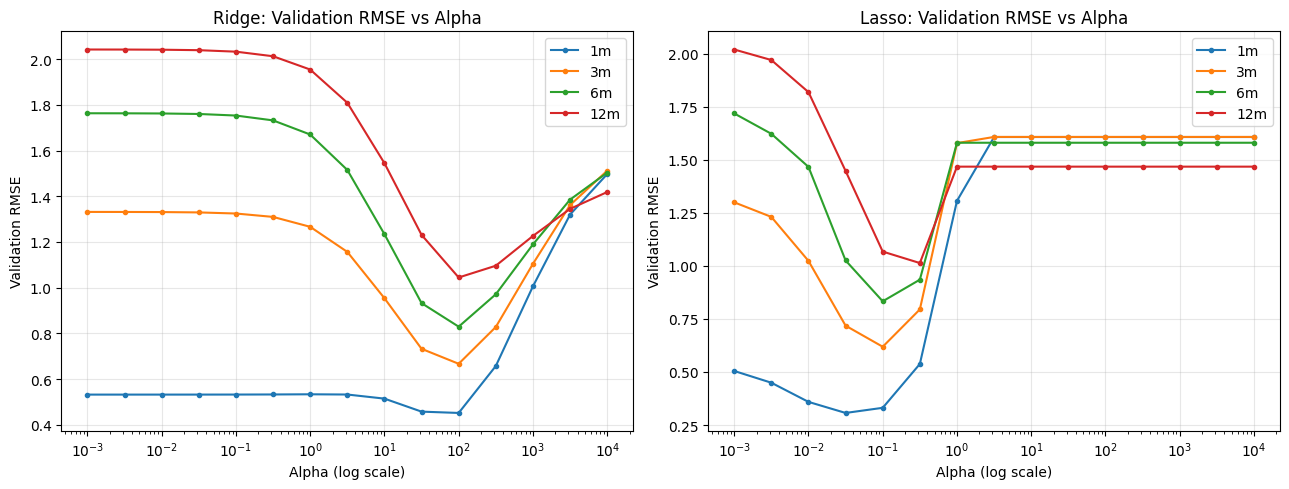

In [ ]:
val_df = main_exp["val_df"]

# Finding best validation score for each model per horizon
val_best_list = []
for h in horizons:
    for name in model_space.keys():
        sub = val_df[(val_df["horizon"] == h) & (val_df["model"] == name)]
        min_rmse = sub["val_RMSE"].min()
        best_row = sub[sub["val_RMSE"] == min_rmse].iloc[0]
        val_best_list.append(best_row)

val_summary = pd.DataFrame(val_best_list)[["horizon", "model", "alpha", "val_MAE", "val_RMSE", "val_R2"]].round(3)
print("Validation Set Performance Across Models")
print(val_summary)

# Printing the summary of selected winning model per horizon
print("Selected Model per Horizon (Lowest Validation RMSE)")
for h in horizons:
    win = main_exp["best_models"][h]
    print(f"Horizon {h:>2}m: {win['model_name']:<18} | Best Hyperparameters: {win['params']}")

# Plot validation RMSE vs alpha for Ridge and Lasso
plt.figure(figsize=(13, 5))

# Ridge tunning curve
plt.subplot(1, 2, 1)
for h in horizons:
    r = val_df[(val_df["model"] == "Ridge") & (val_df["horizon"] == h)].sort_values(by="alpha")
    plt.plot(r["alpha"], r["val_RMSE"], marker="o", markersize=3, label=f"{h}m")
plt.xscale("log")
plt.title("Ridge: Validation RMSE vs Alpha")
plt.xlabel("Alpha (log scale)")
plt.ylabel("Validation RMSE")
plt.legend()
plt.grid(True, alpha=0.3)

# Lasso tuning curve
plt.subplot(1, 2, 2)
for h in horizons:
    l = val_df[(val_df["model"] == "Lasso") & (val_df["horizon"] == h)].sort_values(by="alpha")
    plt.plot(l["alpha"], l["val_RMSE"], marker="o", markersize=3, label=f"{h}m")
plt.xscale("log")
plt.title("Lasso: Validation RMSE vs Alpha")
plt.xlabel("Alpha (log scale)")
plt.ylabel("Validation RMSE")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretation of validation results:**
* **Regularization helps:** Unregularized `LinearRegression` overfits on longer horizons (validation RMSE of 1.76 at 6m and 2.04 at 12m). Ridge and Lasso prevent this by shrinking weights.
* **Tuning curves:** Both plots show clear U-shaped curves with minima around $\alpha = 10^{-2}$ to $10^{2}$.
* **Selected models:** Lasso (alpha $\approx$ 0.032) wins at 1m, Lasso (alpha = 0.10) wins at 3m, Ridge (alpha = 100) wins at 6m, and Lasso (alpha = 0.32) wins at 12m.

### 5.2 Test set evaluation by model and horizon

We evaluate each selected model once on the untouched test set (September 2017 to August 2025) using MAE, RMSE, and $R^2$.

In [ ]:
test_df = main_exp["test_df"]

# Test set evaluation tables across all models and horizons
for metric in ["MAE", "RMSE", "R2"]:
    print(f"Test Set {metric} by Model and Horizon")
    metric_cols = {}
    for h in horizons:
        sub = test_df[test_df["horizon"] == h]
        metric_cols[f"{h}m"] = sub.set_index("model")[f"test_{metric}"]
    table_m = pd.DataFrame(metric_cols).round(3)
    print(table_m)
    print()

# Final test scores for selected models
print("Selected Models Final Test Scores")
selected_test = test_df[test_df["selected"]][["horizon", "model", "test_MAE", "test_RMSE", "test_R2"]].round(3)
print(selected_test)

Test Set MAE by Model and Horizon
                         1m     3m     6m    12m
model                                           
LinearRegression      0.648  1.770  2.631  3.132
Ridge                 0.666  1.021  1.487  1.841
Lasso                 0.379  0.930  1.490  1.703
Baseline: Train Mean  1.610  1.600  1.577  1.597

Test Set RMSE by Model and Horizon
                         1m     3m     6m    12m
model                                           
LinearRegression      0.853  2.426  3.674  4.344
Ridge                 0.983  1.593  2.383  2.908
Lasso                 0.531  1.417  2.373  2.594
Baseline: Train Mean  2.271  2.269  2.269  2.293

Test Set R2 by Model and Horizon
                         1m     3m     6m    12m
model                                           
LinearRegression      0.851 -0.213 -1.807 -2.939
Ridge                 0.802  0.477 -0.181 -0.765
Lasso                 0.942  0.586 -0.171 -0.404
Baseline: Train Mean -0.058 -0.060 -0.071 -0.097

Selected Mode

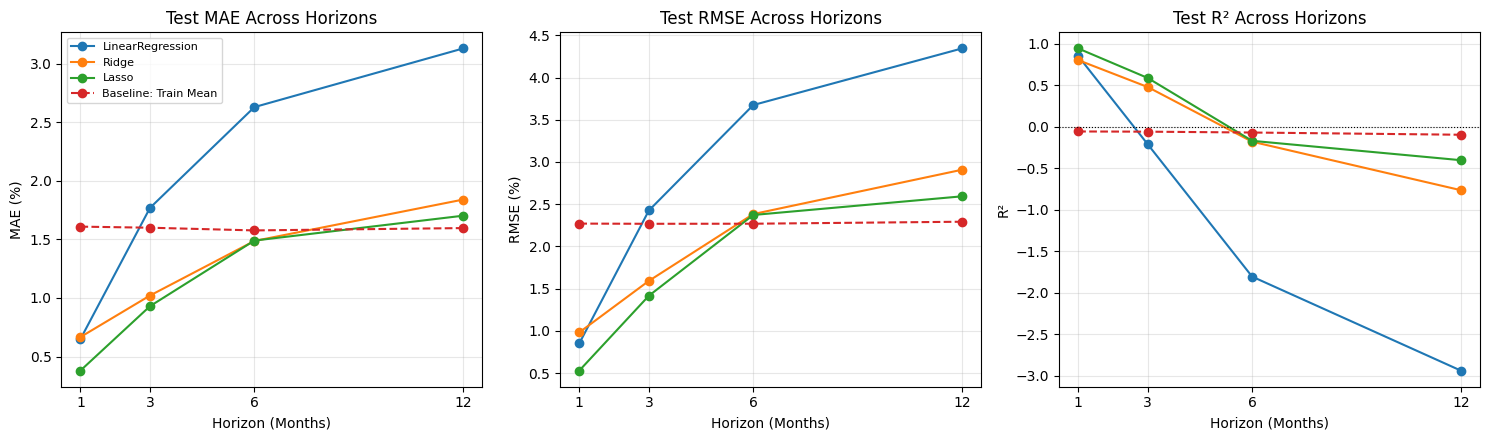

In [ ]:
# Performance vs horizon for all models and baseline
plt.figure(figsize=(15, 4.5))

# MAE
plt.subplot(1, 3, 1)
for m_name in test_df["model"].unique():
    sub = test_df[test_df["model"] == m_name].sort_values(by="horizon")
    ls = "--" if "Baseline" in m_name else "-"
    plt.plot(sub["horizon"], sub["test_MAE"], marker="o", ls=ls, label=m_name)
plt.title("Test MAE Across Horizons")
plt.xlabel("Horizon (Months)")
plt.ylabel("MAE (%)")
plt.xticks(horizons)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=8)

# RMSE
plt.subplot(1, 3, 2)
for m_name in test_df["model"].unique():
    sub = test_df[test_df["model"] == m_name].sort_values(by="horizon")
    ls = "--" if "Baseline" in m_name else "-"
    plt.plot(sub["horizon"], sub["test_RMSE"], marker="o", ls=ls, label=m_name)
plt.title("Test RMSE Across Horizons")
plt.xlabel("Horizon (Months)")
plt.ylabel("RMSE (%)")
plt.xticks(horizons)
plt.grid(True, alpha=0.3)

# R2
plt.subplot(1, 3, 3)
for m_name in test_df["model"].unique():
    sub = test_df[test_df["model"] == m_name].sort_values(by="horizon")
    ls = "--" if "Baseline" in m_name else "-"
    plt.plot(sub["horizon"], sub["test_R2"], marker="o", ls=ls, label=m_name)
plt.axhline(0, color="black", lw=0.8, ls=":")
plt.title("Test R² Across Horizons")
plt.xlabel("Horizon (Months)")
plt.ylabel("R²")
plt.xticks(horizons)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

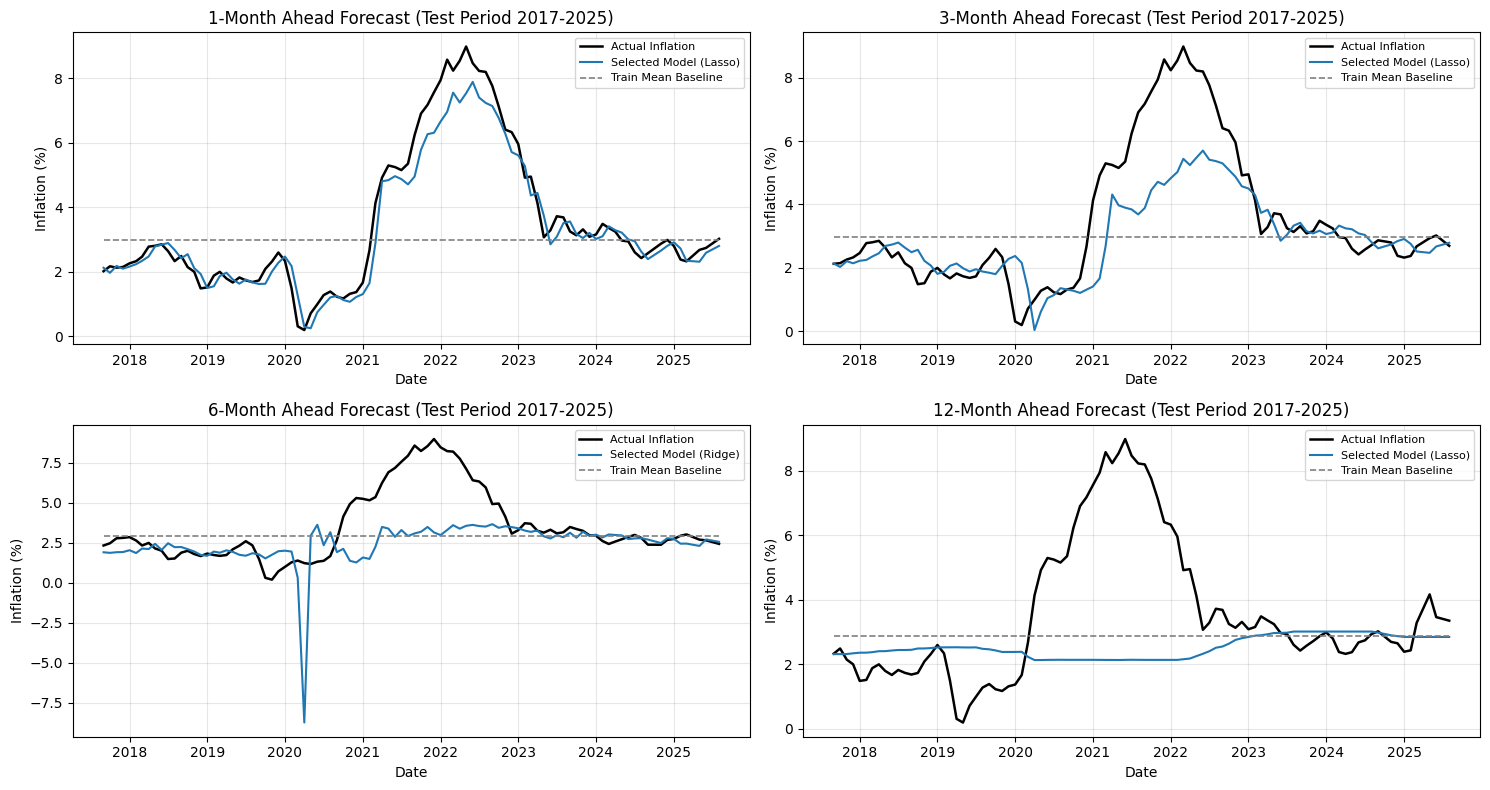

In [ ]:
# Predicted vs actual inflation on the test set
t_idx = main_exp["test_index"]
preds = main_exp["predictions"]

plt.figure(figsize=(15, 8))
for i, h in enumerate(horizons):
    plt.subplot(2, 2, i + 1)
    sel_name = main_exp["best_models"][h]["model_name"]
    plt.plot(t_idx, preds[(h, "actual")], color="black", lw=1.8, label="Actual Inflation")
    plt.plot(t_idx, preds[(h, sel_name)], color="tab:blue", lw=1.5, label=f"Selected Model ({sel_name})")
    plt.plot(t_idx, preds[(h, "Baseline: Train Mean")], color="gray", ls="--", lw=1.2, label="Train Mean Baseline")

    plt.title(f"{h}-Month Ahead Forecast (Test Period 2017-2025)")
    plt.xlabel("Date")
    plt.ylabel("Inflation (%)")
    plt.legend(fontsize=8)
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Macroeconomic Feature Importance and Analysis

To see which indicators matter most for predicting inflation, we examine:
1. **Standardized coefficients:** Because all features are standardized by `StandardScaler` inside the pipeline, the coefficient magnitudes indicate relative importance, while the sign indicates directional impact. Lasso sets unhelpful ones to zero.
2. **Models without current inflation:** Current inflation dominates short horizons. Re-running the pipeline using only the macroeconomic indicators shows the predictive value of labor, production, financial, and commodity indicators on their own.

Standardized Model Coefficients Across Horizons
              1m (Lasso)  3m (Lasso)  6m (Ridge)  12m (Lasso)
inflation          1.080       0.642       0.301        0.000
unrate             0.020       0.000       0.151        0.000
d_unrate          -0.000      -0.007      -0.150       -0.000
y_indpro           0.010       0.020       0.034        0.000
y_payems           0.000       0.000       0.022        0.000
y_ppiaco           0.000       0.000      -0.012       -0.000
y_dcoilwtico       0.144       0.177       0.148       -0.000
y_m2sl            -0.005      -0.009      -0.042       -0.000
t10y2y             0.000       0.000       0.011       -0.000
fedfunds           0.118       0.306       0.464        0.389
houst              0.000       0.000       0.135        0.000
umcsent           -0.000      -0.000      -0.000        0.000


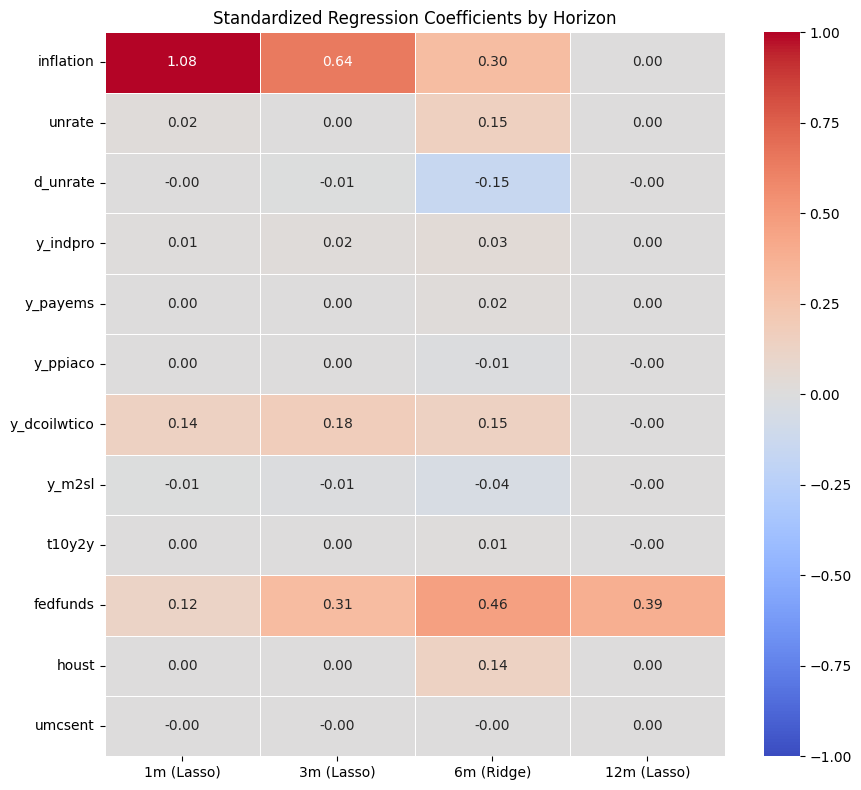

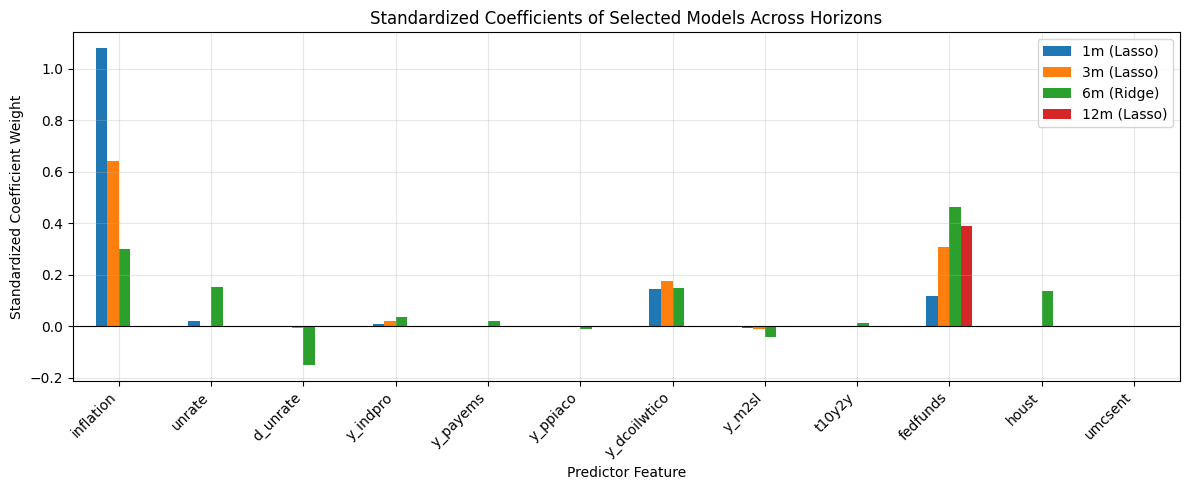

In [ ]:
# Standardised coefficients of the selected model for each horizon
coeff_dict = {}

for h in horizons:
    sel_name = main_exp["best_models"][h]["model_name"]
    pipe = main_exp["fitted"][(h, sel_name)]
    model_step = pipe.named_steps["model"]

    # Get the learned weights/coefficients from the fitted model
    weights = model_step.coef_
    coeff_dict[f"{h}m ({sel_name})"] = weights

coeff_df = pd.DataFrame(coeff_dict, index=features).round(3)
print("Standardized Model Coefficients Across Horizons")
print(coeff_df)

plot_heatmap(coeff_df, "Standardized Regression Coefficients by Horizon", figsize=(9, 8))

# Bar chart of model coefficients across horizons
coeff_df.plot(kind="bar", figsize=(12, 5))
plt.title("Standardized Coefficients of Selected Models Across Horizons")
plt.xlabel("Predictor Feature")
plt.ylabel("Standardized Coefficient Weight")
plt.axhline(0, color="black", lw=0.8)
plt.xticks(rotation=45, ha="right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Macro-Only Selected Models Test Scores
    horizon  model  test_MAE  test_RMSE  test_R2
2         1  Lasso     1.001      1.489    0.545
6         3  Lasso     1.354      2.075    0.113
9         6  Ridge     1.624      2.592   -0.397
14       12  Lasso     1.703      2.594   -0.404
Macro-Only Standardized Coefficients
              1m (Lasso)  3m (Lasso)  6m (Ridge)  12m (Lasso)
unrate             0.000       0.000       0.142        0.000
d_unrate           0.000      -0.000      -0.146       -0.000
y_indpro          -0.000       0.000       0.029        0.000
y_payems          -0.000       0.000       0.037        0.000
y_ppiaco           0.586       0.305       0.102       -0.000
y_dcoilwtico       0.141       0.250       0.187       -0.000
y_m2sl            -0.069      -0.086      -0.077       -0.000
t10y2y             0.028       0.061       0.020       -0.000
fedfunds           0.668       0.702       0.587        0.389
houst             -0.000       0.000       0.130        0.0

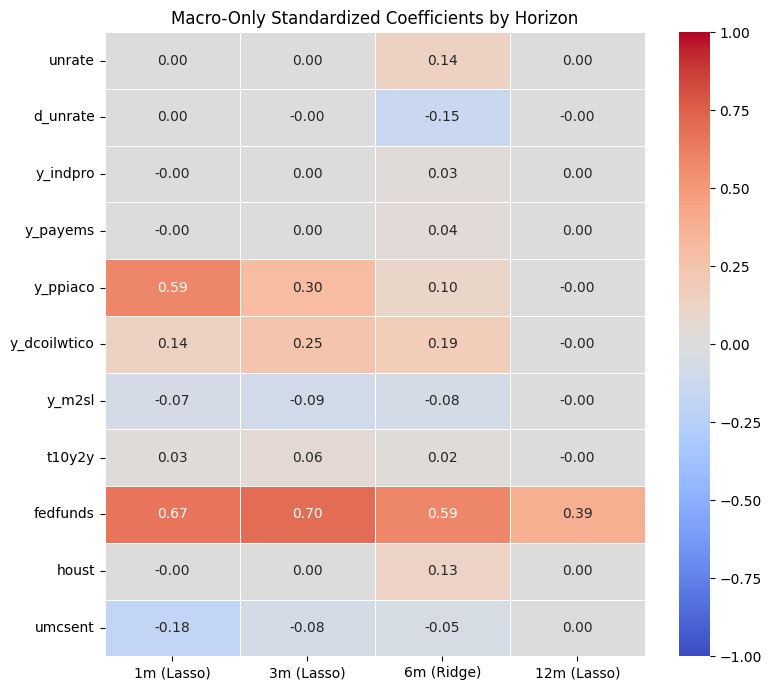

In [ ]:
# Experiment using only macroeconomic indicators (without current inflation)
macro_exp = run_experiment(macro_features, "Macro Indicators Only")
macro_test = macro_exp["test_df"]

print("Macro-Only Selected Models Test Scores")
macro_selected = macro_test[macro_test["selected"]][["horizon", "model", "test_MAE", "test_RMSE", "test_R2"]].round(3)
print(macro_selected)

# Macro-only standardized coefficients
macro_coeff_dict = {}
for h in horizons:
    sel_name = macro_exp["best_models"][h]["model_name"]
    pipe = macro_exp["fitted"][(h, sel_name)]
    weights = pipe.named_steps["model"].coef_
    macro_coeff_dict[f"{h}m ({sel_name})"] = weights

macro_coeff_df = pd.DataFrame(macro_coeff_dict, index=macro_features).round(3)
print("Macro-Only Standardized Coefficients")
print(macro_coeff_df)

plot_heatmap(macro_coeff_df, "Macro-Only Standardized Coefficients by Horizon", figsize=(8, 7))

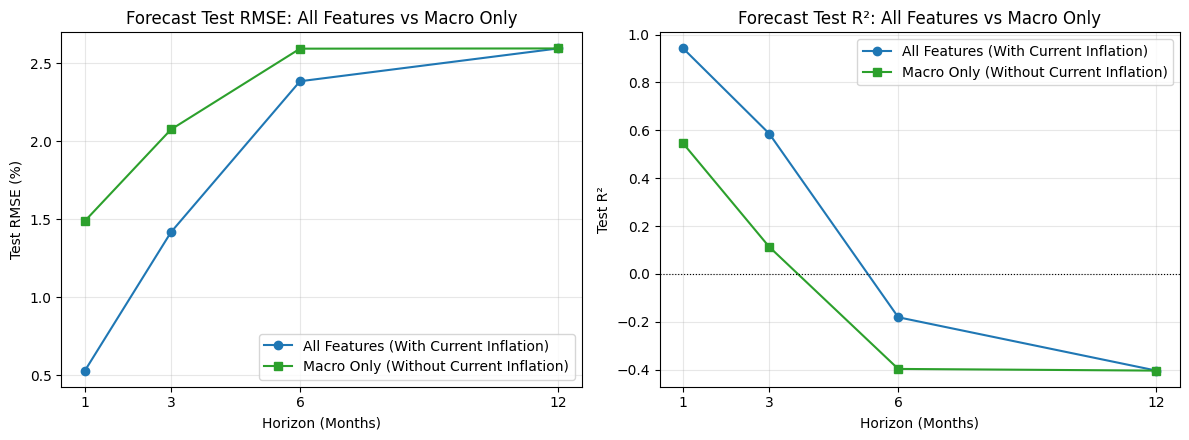

In [ ]:
# Compare all features vs macro-only features across horizons
plt.figure(figsize=(12, 4.5))

# RMSE Comparison
plt.subplot(1, 2, 1)
all_sel_rmse = main_exp["test_df"][main_exp["test_df"]["selected"]].sort_values(by="horizon")["test_RMSE"].values
macro_sel_rmse = macro_test[macro_test["selected"]].sort_values(by="horizon")["test_RMSE"].values

plt.plot(horizons, all_sel_rmse, marker="o", color="tab:blue", label="All Features (With Current Inflation)")
plt.plot(horizons, macro_sel_rmse, marker="s", color="tab:green", label="Macro Only (Without Current Inflation)")
plt.title("Forecast Test RMSE: All Features vs Macro Only")
plt.xlabel("Horizon (Months)")
plt.ylabel("Test RMSE (%)")
plt.xticks(horizons)
plt.legend()
plt.grid(True, alpha=0.3)

# R2 Comparison
plt.subplot(1, 2, 2)
all_sel_r2 = main_exp["test_df"][main_exp["test_df"]["selected"]].sort_values(by="horizon")["test_R2"].values
macro_sel_r2 = macro_test[macro_test["selected"]].sort_values(by="horizon")["test_R2"].values

plt.plot(horizons, all_sel_r2, marker="o", color="tab:blue", label="All Features (With Current Inflation)")
plt.plot(horizons, macro_sel_r2, marker="s", color="tab:green", label="Macro Only (Without Current Inflation)")
plt.axhline(0, color="black", lw=0.8, ls=":")
plt.title("Forecast Test R²: All Features vs Macro Only")
plt.xlabel("Horizon (Months)")
plt.ylabel("Test R²")
plt.xticks(horizons)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Summary and Discussion

### Summary of performance findings

In [ ]:
# Summary of final results across horizons
print(f"Full Sample Period: {model_data.index.min().date()} to {model_data.index.max().date()} ({len(model_data)} months)")
print(f"Test Period       : {xtr.index[-1].date()} onward ({len(xte)} months)")

for h in horizons:
    sel_row = main_exp["test_df"][(main_exp["test_df"]["horizon"] == h) & (main_exp["test_df"]["selected"])].iloc[0]
    base_row = main_exp["test_df"][(main_exp["test_df"]["horizon"] == h) & (main_exp["test_df"]["model"] == "Baseline: Train Mean")].iloc[0]

    better_base = "beats" if sel_row["test_RMSE"] < base_row["test_RMSE"] else "does not beat"
    print(f"Horizon {h:>2}m | Model: {sel_row['model']:<16} | RMSE={sel_row['test_RMSE']:.3f}  MAE={sel_row['test_MAE']:.3f}  R2={sel_row['test_R2']:+.3f} | Baseline RMSE={base_row['test_RMSE']:.3f} -> {better_base} baseline")

Full Sample Period: 1987-01-01 to 2025-08-01 (461 months)
Test Period       : 2009-12-01 onward (93 months)
Horizon  1m | Model: Lasso            | RMSE=0.531  MAE=0.379  R2=+0.942 | Baseline RMSE=2.271 -> beats baseline
Horizon  3m | Model: Lasso            | RMSE=1.417  MAE=0.930  R2=+0.586 | Baseline RMSE=2.269 -> beats baseline
Horizon  6m | Model: Ridge            | RMSE=2.383  MAE=1.487  R2=-0.181 | Baseline RMSE=2.269 -> does not beat baseline
Horizon 12m | Model: Lasso            | RMSE=2.594  MAE=1.703  R2=-0.404 | Baseline RMSE=2.293 -> does not beat baseline


### Final disscussion

**1. Data and sample:**
The dataset combine the 11 monthly US economic series data form the FRED source. It goes form Jan 1986 to about late 2026. We are restircting the analysis to the common sample period and further construct the 12 months gowth rates, further forecasting the targets in (1, 3, 6, 12) months. Totla yield about 461 complete mothly obesrvation that belong to the range Jan 1987 to Aug 2025.

**2. Accuracy vs horizon:**
we can see that the predictive accuracy goes on decreasing as the horizon increases:
* At the 1-month horizon- the forecasting accuracy is the highest. Here, inflation shows strog persistance, so we can say that the inflaction for the month t provides a strong hint for hte inflation in the month t+1.
* The information overlapping decreases for the 3, 6, 12 months. Thus, the accuracy decreases, RSME increases and R2 decreases significantly.

**3. Model comparison:**
* **Ordinary least squares (`LinearRegression`):** Overfits badly in the presence of correlated predictors, giving higher test error at longer horizons.
* **Ridge and lasso regression:** Regularization prevents runaway parameter weights. Lasso performs feature selection by shrinking coefficients of redundant variables to zero, while the Ridge provides smooth shrinkage. However, both regularized models consistently beat unregularized OLS.

**4. Baseline comparison and the regime shift:**
* At short horizons (like 1m and 3m), the models beat the training mean baseline by a wide margin.
* At the 12-month horizon, linear models struggle on the test set. This is because the test period (2017–2025) contains the post-COVID inflation spike reaching nearly 9% in 2022—an event unseen in the training sample (1987–2009). The reason being linear models trained on calmer earlier years cannot predict this extreme spike one year ahead.

**5. Most useful macroeconomic indicators:**
* **Short horizons (1m–3m):** Current inflation (`inflation`) is the dominant predictor, followed by Producer Price Index growth (`y_ppiaco`) and crude oil price growth (`y_dcoilwtico`).
* **Medium-to-long horizons (6m–12m):** In the macro-only models without current inflation, monetary and financial variables—specifically the Federal Funds rate (`fedfunds`), the Treasury yield spread (`t10y2y`), and money supply growth (`y_m2sl`)—alongside labor indicators (`unrate`, `d_unrate`) carry the most persistent predictive signal.

**6. Limitations:**
* The models used are linear models (LinearRegression, Ridge, Lasso). Whereas real macroeconomic relationships can have non-linear effects and regime shifts.
* Macroeconomic data are revised historically by statistical agencies, whereas real-time forecasting works with preliminary releases.